# DNA methylation in TCGA head and neck tumours

**Musalula Sinkala · Reusable Python analysis notebook**

This notebook runs the patient-level analysis underlying
*DNA methylation differs between head and neck tumours from Black
and White patients*. Each computational section calls the
`hnsc_methylation` package; the notebook presents the workflow
and selected outputs.

AFR and EUR abbreviate the recorded clinical race categories
**Black or African American** and **White**. They do not denote
genotype-derived ancestry. The analysis is observational, and
within-cohort discrimination does not establish a causal mechanism
or externally validated clinical utility.

After installing the environment described in the repository
README, select that environment's Python kernel and choose
**Restart Kernel and Run All Cells**. The bundled inputs are
sufficient; this notebook does not download study data.

## 1. Locate the repository and select the run settings

Run the notebook from either the repository root or its
`notebooks` folder. The paper settings use seed 42 in the analysis
functions and **100 classifier label permutations**. The full
run includes repeated model fits and exact CpG–gene correlations;
the classification and expression stages may take time.

For an exploratory smoke run, change `PERMUTATIONS` to 2 and
`OUTPUT_NAME` to `results-quick`. Such a run checks execution but
is **not a reproduction of the paper's permutation analysis**.
Restore 100 before interpreting manuscript-level validation.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

def find_repository(start):
    for candidate in (start, *start.parents):
        if ((candidate / "pyproject.toml").is_file()
                and (candidate / "src" / "hnsc_methylation").is_dir()):
            return candidate
    raise FileNotFoundError(
        "Open this notebook from the repository root or notebooks folder."
    )

ROOT = find_repository(Path.cwd().resolve())
from hnsc_methylation.pipeline import PipelineConfig, MethylationPipeline

PERMUTATIONS = 100
OUTPUT_NAME = "results"
config = PipelineConfig(
    repo_root=ROOT,
    output_dir=ROOT / OUTPUT_NAME,
    permutations=PERMUTATIONS,
)
pipeline = MethylationPipeline(config)
TABLES = config.output_dir / "tables"
FIGURES = config.output_dir / "figures"
print(f"Python {sys.version.split()[0]}; permutations: {PERMUTATIONS}")
print(f"Output folder: {OUTPUT_NAME}")
if PERMUTATIONS != 100:
    display(Markdown("**Exploratory run: permutation results are not paper settings.**"))

def show_table(filename, rows=10):
    table = pd.read_csv(TABLES / filename, sep="\t")
    display(table.head(rows))
    print(f"{len(table):,} rows in {filename}")
    return table

def show_json(filename):
    payload = json.loads((TABLES / filename).read_text())
    display(payload)
    return payload

Python 3.14.6; permutations: 100
Output folder: results


## 2. Verify the bundled inputs

Checksums establish the identity of the input files before
analysis. The data provenance records distinguish processed TCGA
measurements, clinical metadata, frozen probe annotations and
imported manuscript summaries. A failed input check should be
resolved before proceeding.

In [2]:
input_checks = pipeline.verify_inputs()
display(input_checks)

verify_inputs: complete (1.1 s)


{'integrity': {'stored_files_checked': 80, 'input_bytes_verified': 542539905},
 'prepared_inputs': {'methylation_clean': 'data/prepared/data_methylation_hm27_hm450_merged_clean.txt',
  'methylation_raw': 'data/prepared/data_methylation_hm27_hm450_merged.txt',
  'clinical_patient': 'data/prepared/data_clinical_patient.txt',
  'clinical_sample': 'data/prepared/data_clinical_sample.txt',
  'expression': 'data/prepared/data_mrna_seq_v2_rsem.txt'}}

## 3. Prepare the patient cohort

Match primary-tumour methylation profiles to clinical records by
TCGA patient identifier. Clinical group, age, sex, HPV status,
stage and anatomical site form the analysis covariates. Unknown
HPV status and stage remain explicit categories.

In [3]:
cohort = pipeline.prepare_cohort()
display(cohort.head() if isinstance(cohort, pd.DataFrame) else cohort)

prepare_cohort: complete (1.0 s)


,matrix_sample,patient_id,group,source_race_label,age,male,stage,hpv_positive,hpv_unknown,site,icd_o_3_site,radiation,os_months,os_event,pfs_months,weight,stage_iv
0,TCGA_4P_AA8J_01,TCGA-4P-AA8J,AFR,Black or African American,66.0,1,IV,0,0,Oral cavity,C02.9,No,3.353388,0,3.353388,NaN,1
1,TCGA_BA_4074_01,TCGA-BA-4074,EUR,White,69.0,1,IV,0,0,Oral cavity,C02.9,Yes,15.188875,1,13.019035,NaN,1
2,TCGA_BA_4076_01,TCGA-BA-4076,EUR,White,39.0,1,Unknown,0,0,Larynx,C32.9,Yes,13.643686,1,9.402637,NaN,0
3,TCGA_BA_4078_01,TCGA-BA-4078,EUR,White,83.0,1,Unknown,0,0,Larynx,C32.9,Yes,9.073873,1,9.073873,NaN,0
4,TCGA_BA_5149_01,TCGA-BA-5149,EUR,White,47.0,1,IV,0,0,Oral cavity,C04.9,Yes,26.498340,1,12.788901,NaN,1


## 4. Apply the probe annotation rule

The outcome-independent rule requires membership in both platform
manifests and excludes the union of general-quality and AFR/EUR
population-SNP flags. A missing row in a sparse mask means no
listed flag only after manifest coverage has been established.

In [4]:
pipeline.annotate_probes()
probe_annotations = show_table("probe_quality_annotations.tsv", rows=6)
display(probe_annotations["eligible_primary"].value_counts().rename("probes"))

annotate_probes: complete (2.2 s)


,Entity_Stable_Id,HugoSymbol,Location,HM27_manifest_covered,HM27_mask_row_present,HM27_mask,HM27_maskUniq,HM27_general_mask,HM27_population_SNP_mask,HM27_annotation_status,...,HM450_maskUniq,HM450_general_mask,HM450_population_SNP_mask,HM450_annotation_status,covered_both_platforms,general_mask_union,population_SNP_mask_union,technical_mask_union,eligible_primary,exclusion_reason
0,cg00000292,ATP2A1,1stExon,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN
1,cg00003994,MEOX2,1stExon,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN
2,cg00005847,HOXD3,5'UTR,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN
3,cg00007981,PANX1,1stExon,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN
4,cg00008713,IMPA2,TSS1500,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN
5,cg00009407,TTC8,TSS200,True,False,NaN,NaN,False,False,covered_no_listed_flags,...,NaN,False,False,covered_no_listed_flags,True,False,False,False,True,NaN


22,601 rows in probe_quality_annotations.tsv


eligible_primary
True     21791
False      810
Name: probes, dtype: int64

## 5. Fit differential methylation models

Probe-wise models use observed M-values and adjust for the
clinical covariates with HC3 standard errors. Benjamini–Hochberg
correction is applied across the eligible probes. Reportable
DMPs meet both q < 0.05 and |AFR − EUR delta beta| ≥ 0.05.

In [5]:
pipeline.differential_methylation()
differential = pd.read_csv(TABLES / "differential_methylation_all_probes.tsv", sep="\t")
display(differential.loc[differential["reportable_DMP"]].sort_values("q_adjusted"))
print(f"{len(differential):,} eligible probes; {differential['reportable_DMP'].sum():,} DMPs")

differential_methylation: complete (3.1 s)


,Entity_Stable_Id,HugoSymbol,Location,primary_gene,primary_location,n_AFR,n_EUR,mean_beta_AFR,mean_beta_EUR,delta_beta_AFR_minus_EUR,...,p_adjusted_ordinary_OLS,q_adjusted_ordinary_OLS,missing_fraction_AFR,missing_fraction_EUR,p_group_missingness,q_group_missingness,high_completeness,missing_fraction,reportable_DMP,direction
13735,cg26131019,LRIG1,1stExon,LRIG1,1stExon,47,334,0.070203,0.287650,-0.217447,...,1.044095e-38,2.275188e-34,0.000000,0.254464,0.000004,0.092716,False,0.230303,True,EUR hypermethylated
18145,cg04009666,POLG2,1stExon,POLG2,1stExon,47,447,0.095236,0.044866,0.050370,...,7.631840e-33,8.315271e-29,0.000000,0.002232,1.000000,1.000000,True,0.002020,True,AFR hypermethylated
2566,cg04878842,ERCC2,TSS1500,ERCC2,TSS1500,41,420,0.233893,0.115987,0.117906,...,8.278125e-15,4.509716e-11,0.127660,0.062500,0.120433,1.000000,False,0.068687,True,AFR hypermethylated
4476,cg08634464,ZNF57,Body,ZNF57,Body,46,390,0.140250,0.305957,-0.165707,...,5.727689e-10,1.134655e-06,0.021277,0.129464,0.030243,1.000000,False,0.119192,True,EUR hypermethylated
7421,cg14159672,PM20D1,1stExon,PM20D1,1stExon,47,448,0.475107,0.656598,-0.181491,...,5.023582e-06,2.606402e-03,0.000000,0.000000,1.000000,1.000000,True,0.000000,True,EUR hypermethylated
2262,cg04330449,NEUROG1,1stExon,NEUROG1,1stExon,47,448,0.569118,0.463945,0.105173,...,3.790555e-04,6.453124e-02,0.000000,0.000000,1.000000,1.000000,True,0.000000,True,AFR hypermethylated
6238,cg11948328,HSD17B12,1stExon,HSD17B12,1stExon,47,448,0.158278,0.096283,0.061994,...,5.244811e-13,1.428621e-09,0.000000,0.000000,1.000000,1.000000,True,0.000000,True,AFR hypermethylated
15936,cg13174197,GNL3/PBRM1,Body/TSS1500,GNL3,Body,47,447,0.130190,0.076599,0.053591,...,3.733013e-14,1.355768e-10,0.000000,0.002232,1.000000,1.000000,True,0.002020,True,AFR hypermethylated
14602,cg00669623,CDK11A/CDK11B,TSS200,CDK11A,TSS200,47,448,0.218275,0.095904,0.122371,...,3.258473e-24,2.366846e-20,0.000000,0.000000,1.000000,1.000000,True,0.000000,True,AFR hypermethylated
13054,cg24826867,IRF8,5'UTR,IRF8,5'UTR,47,448,0.502121,0.444642,0.057479,...,7.097753e-03,2.771813e-01,0.000000,0.000000,1.000000,1.000000,True,0.000000,True,AFR hypermethylated


21,791 eligible probes; 17 DMPs


## 6. Estimate matched methylation–expression associations

Correlate exact CpG–gene pairs using pairwise-complete patient
measurements. Multiple-testing correction is separate for the
full cohort, AFR and EUR groups; the displayed primary results
use quality-eligible probes. These unadjusted Spearman
associations are descriptive molecular relationships.

In [6]:
pipeline.expression_associations()
expression = show_table("methylation_expression_correlations.tsv", rows=8)

expression_associations: complete (10.0 s)


,Entity_Stable_Id,HugoSymbol,Location,Group,spearman_r,p_value,n,methylMean,mrnaMean,q_value,regulatory_signal
0,cg00000292,ATP2A1,1stExon,All,-0.022110,0.626441,487,0.616990,486.109727,0.713946,False
1,cg00003994,MEOX2,1stExon,All,-0.209645,0.000003,487,0.302855,30.489892,0.000016,False
2,cg00005847,HOXD3,5'UTR,All,0.189609,0.000025,487,0.588755,14.682382,0.000111,False
3,cg00007981,PANX1,1stExon,All,-0.045363,0.317782,487,0.025919,1024.715380,0.424060,False
4,cg00008713,IMPA2,TSS1500,All,0.055882,0.218321,487,0.054684,2579.216762,0.312694,False
5,cg00009407,TTC8,TSS200,All,0.124926,0.005769,487,0.033927,292.050778,0.014335,False
6,cg00012792,MUTED,Body,All,0.206675,0.000004,487,0.073585,238.524657,0.000022,False
7,cg00016968,RHOC,TSS1500,All,-0.139077,0.002096,487,0.543346,4976.079959,0.005837,False


72,828 rows in methylation_expression_correlations.tsv


## 7. Evaluate out-of-fold clinical-group classification

All data-dependent preprocessing is fitted within training
folds. Five-fold stratified cross-validation estimates held-out
discrimination; the feature-count series and 100 whole-pipeline
label permutations use fixed analysis settings.

In [7]:
pipeline.classification()
classifier_metrics = show_json("classifier_metrics.json")

classification: complete (24.0 s)


{'roc_auc': 0.9080072188449848,
 'average_precision': 0.4964295396946072,
 'balanced_accuracy': 0.8125949848024316,
 'clinical_roc_auc': 0.5958396656534954,
 'clinical_average_precision': 0.12909677076935924,
 'permutation_p_roc_auc': 0.009900990099009901}

## 8. Fit candidate survival models

Fit covariate-adjusted Cox models for the reportable DMPs using
observed beta measurements. Main effects and interactions have
separate multiple-testing families. The broader survival-screen
summaries are **frozen imported manuscript data** from a
separate analysis; the Python workflow does not claim to rerun
that original complete screen. Patient-level illustrated
survival curves are computed from the bundled measurements.

In [8]:
pipeline.survival_models()
survival = show_table("candidate_survival_models.tsv", rows=8)

survival_models: complete (1.0 s)


,Entity_Stable_Id,HugoSymbol,Location,delta_beta_AFR_minus_EUR,q_adjusted_methylation,n,events,hr_per_0_1_beta,ci_low,ci_high,p_cox,ph_test_p,concordance,interaction_hr,interaction_ci_low,interaction_ci_high,p_interaction,q_cox,q_interaction
0,cg13174197,GNL3/PBRM1,Body/TSS1500,0.053591,1.472240e-04,494,207,1.451645,1.057148,1.993358,0.021254,0.295382,0.643295,1.068321,0.558121,2.044916,0.841870,0.258189,0.869406
1,cg08634464,ZNF57,Body,-0.165707,1.366053e-05,436,184,1.089761,1.000867,1.186550,0.047712,0.398070,0.638398,0.810215,0.610893,1.074572,0.144082,0.258189,0.612350
2,cg26131019,LRIG1,1stExon,-0.217447,1.935031e-60,381,152,0.881305,0.771394,1.006876,0.063008,0.275242,0.669843,0.821954,0.396276,1.704895,0.598378,0.258189,0.869406
3,cg00669623,CDK11A/CDK11B,TSS200,0.122371,3.462550e-04,495,208,1.197320,0.983850,1.457107,0.072263,0.110220,0.648404,0.763824,0.545832,1.068875,0.116075,0.258189,0.612350
4,cg02388150,SFRP1,Body,0.130373,3.564226e-02,495,208,1.068808,0.993080,1.150312,0.075938,0.361963,0.645802,1.088769,0.873731,1.356730,0.448704,0.258189,0.847551
5,cg04009666,POLG2,1stExon,0.050370,9.064778e-08,494,208,1.353653,0.885446,2.069439,0.162056,0.948463,0.645741,0.891465,0.343693,2.312265,0.813235,0.444295,0.869406
6,cg19504245,TNNT1,TSS200,0.077306,2.119748e-02,495,208,1.078119,0.965139,1.204325,0.182945,0.041794,0.649458,1.132300,0.827460,1.549443,0.437488,0.444295,0.847551
7,cg11948328,HSD17B12,1stExon,0.061994,1.472240e-04,495,208,0.855010,0.665130,1.099096,0.221510,0.455054,0.642498,0.921950,0.507397,1.675202,0.789698,0.470708,0.869406


17 rows in candidate_survival_models.tsv


## 9. Check numerical and design robustness

The checks include independent HC3 verification, comparison of
Benjamini–Hochberg values, HPV-negative disease, a training-fold
completeness restriction, and held-out collection centres. The
completeness and centre-held-out analyses are separate
sensitivities; they are not a combined restriction.

In [9]:
pipeline.robustness_checks()
robustness = show_table("classifier_robustness_metrics.tsv")

robustness_checks: complete (3.7 s)


,model,roc_auc,average_precision,balanced_accuracy
0,High completeness,0.670830,0.196368,0.610539
1,Held-out collection centres,0.922967,0.632537,0.806421


2 rows in classifier_robustness_metrics.tsv


## 10. Generate the figure set

Figures use the recalculated patient-level results together with
explicitly identified frozen imported summaries. The KEGG GSEA
table is an **imported RNA-expression result**; no new GSEA is
performed here. Its absolute signal-to-noise ranking means the
sign of NES does not assign an AFR or EUR direction.

figures: complete (13.7 s)


**figure1 cohort and methylome structure**

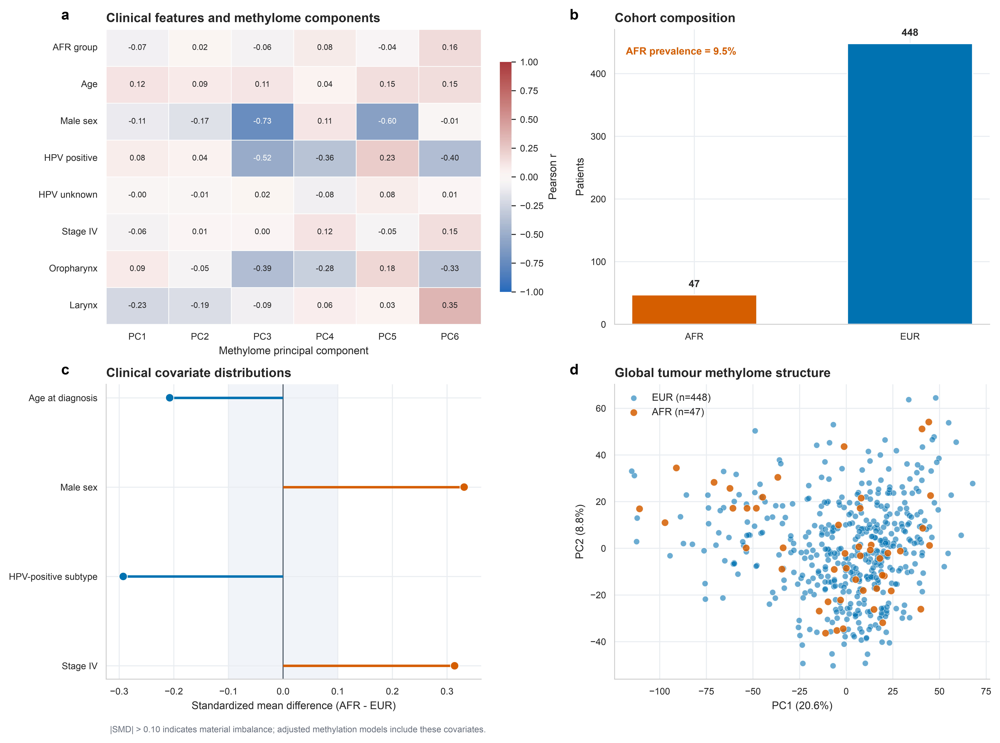

**figure2 differential methylation landscape**

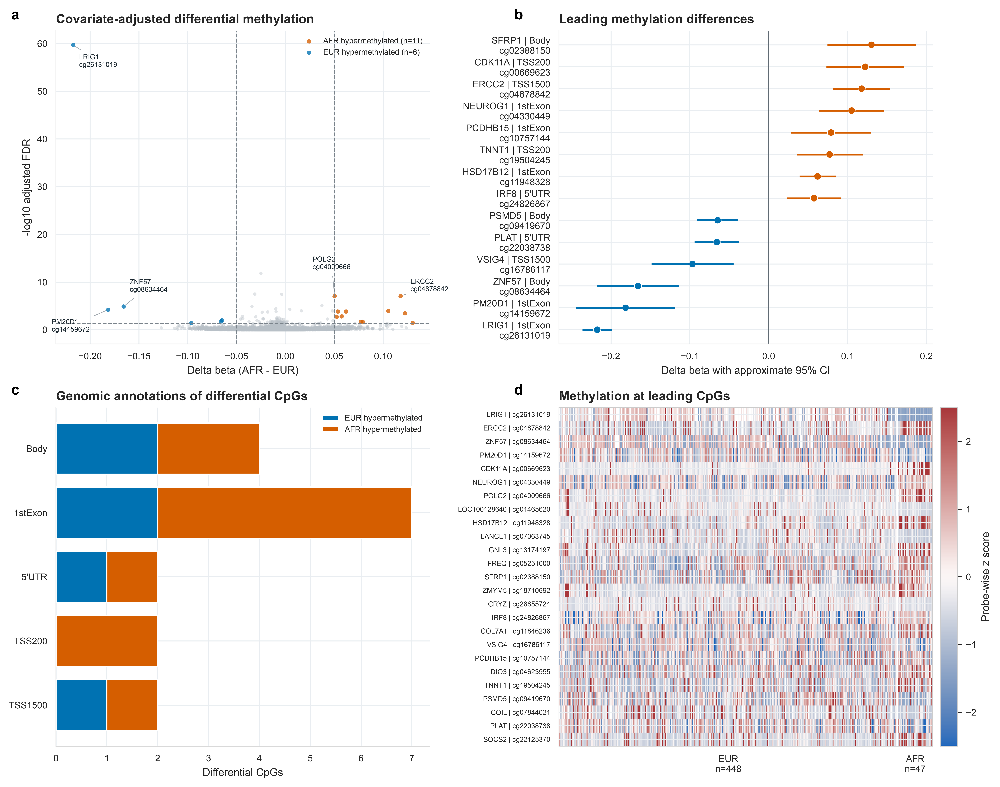

**figure3 cross validated group separability**

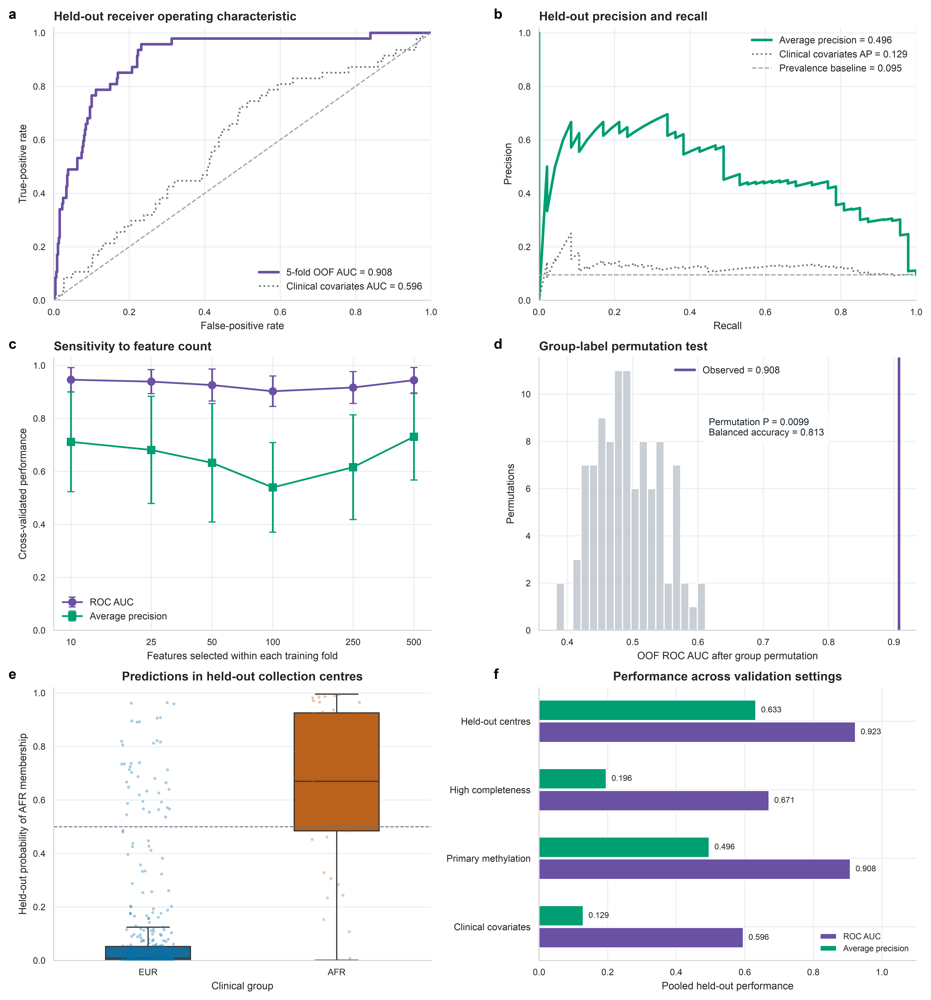

**figure4 methylation expression coupling**

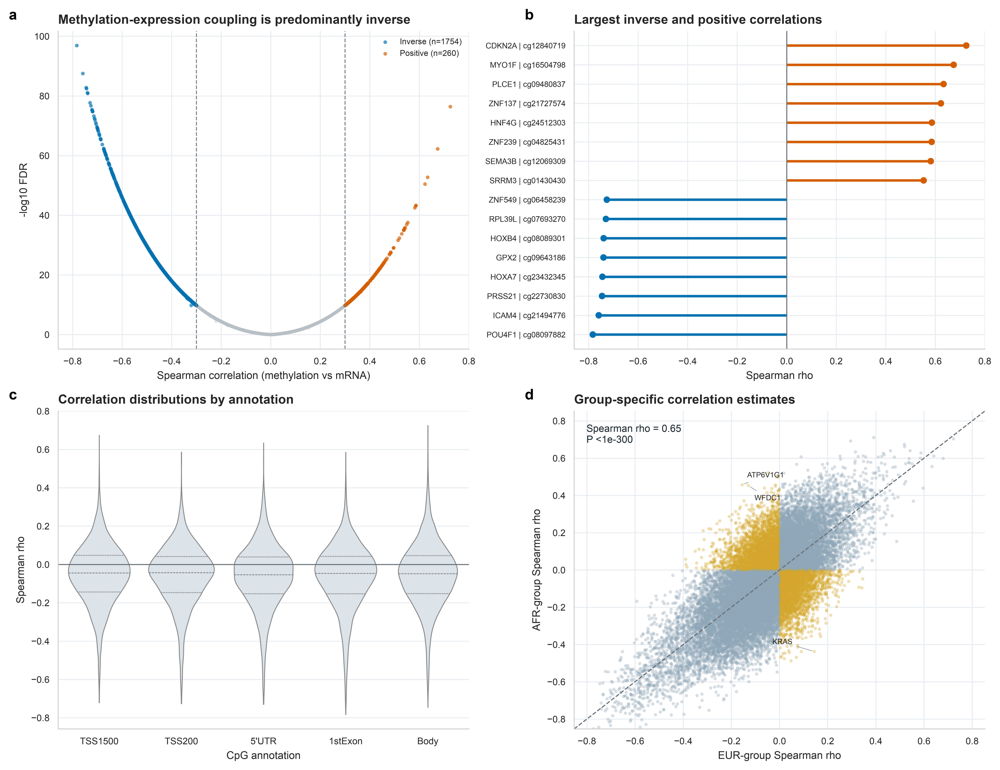

**figure5 survival prioritisation**

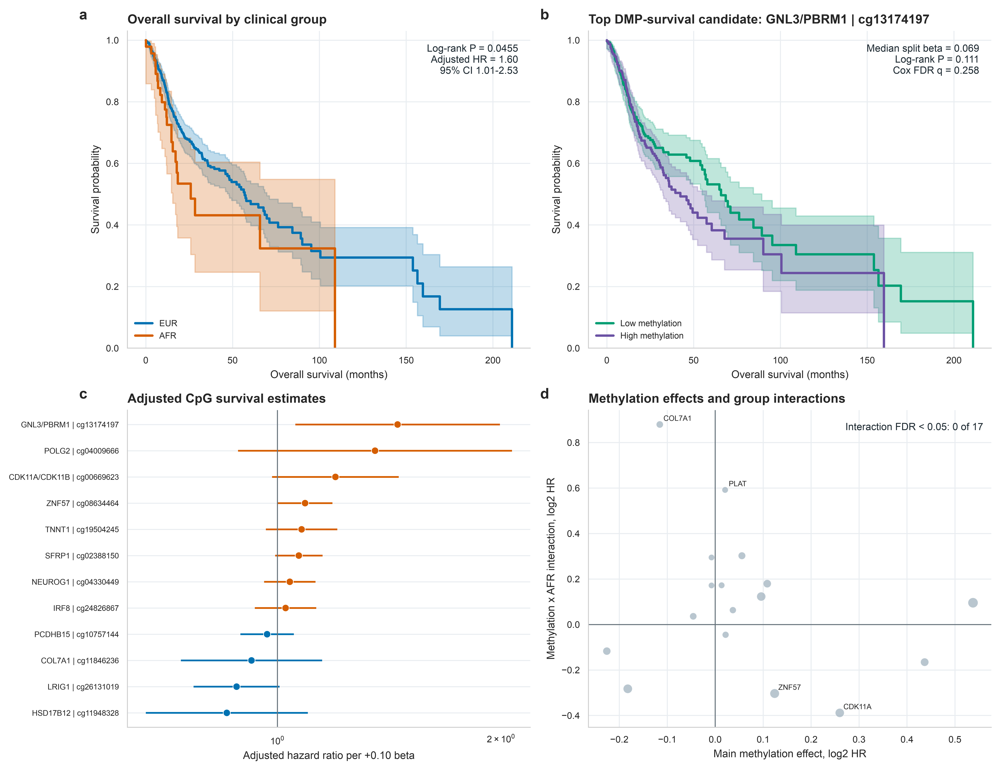

**figure6 survival patterns across 77 cpg candidates**

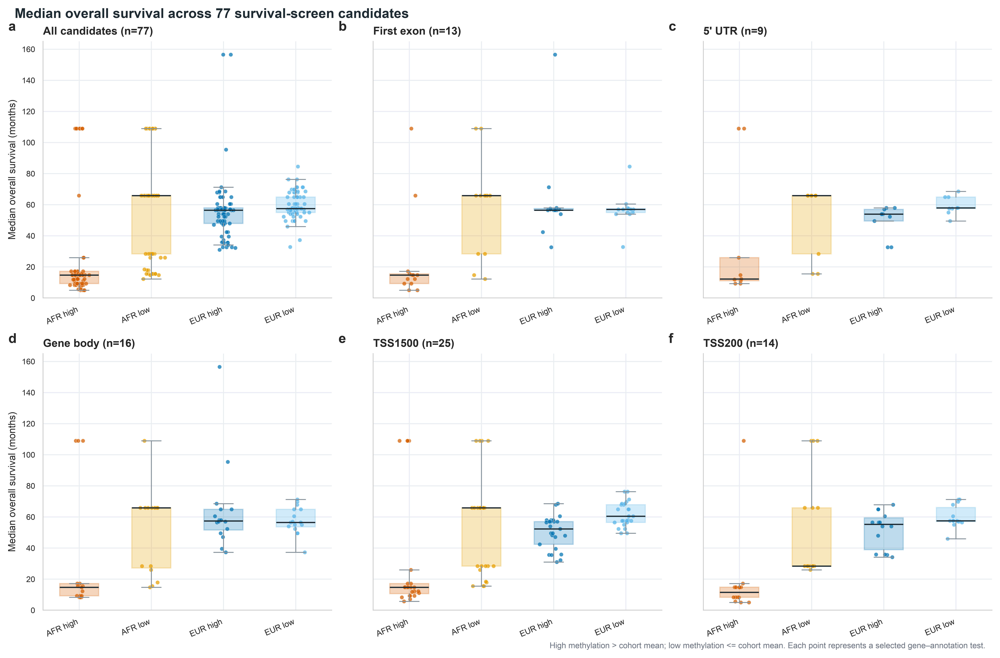

**figure7 fzr1 slc6a20 survival stratification**

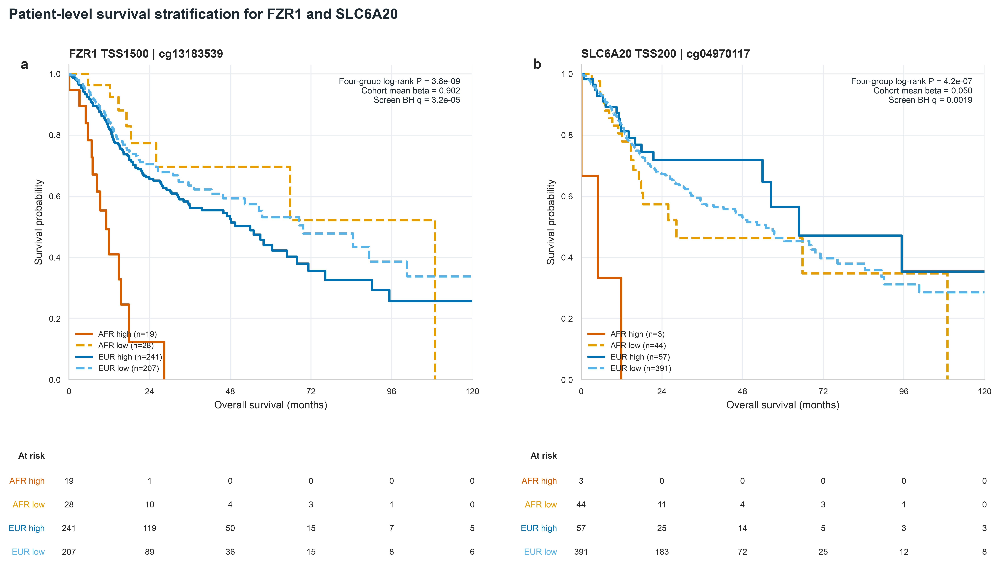

**figure8 pathway and evidence synthesis**

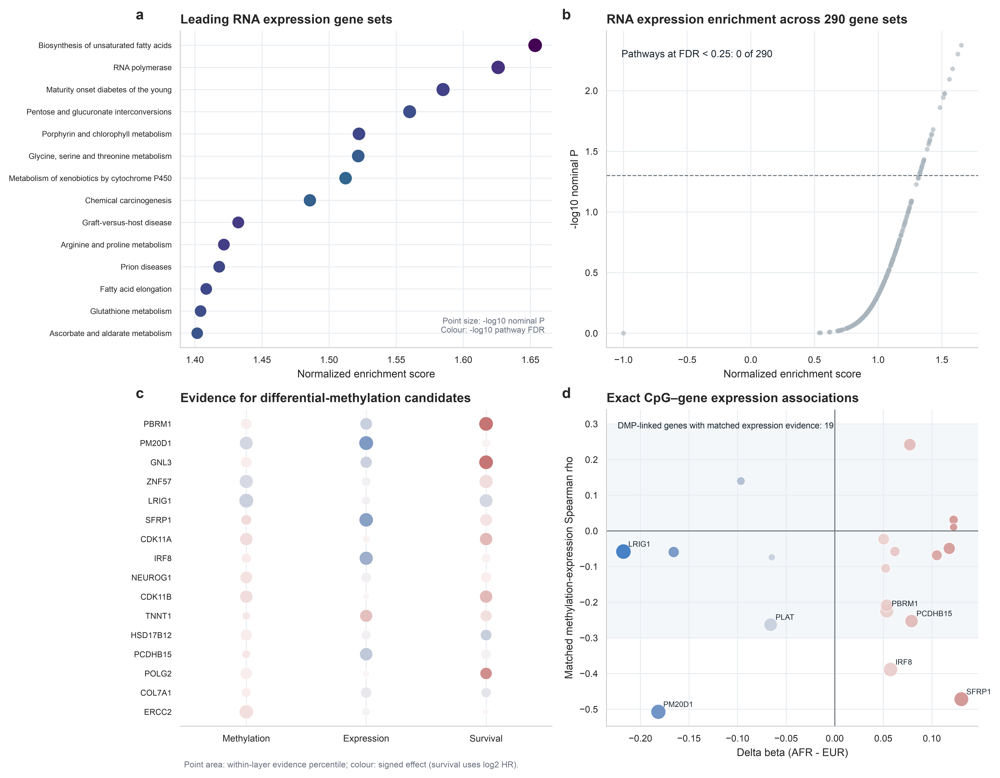

**supplementary figureS1 methylation qc and robustness**

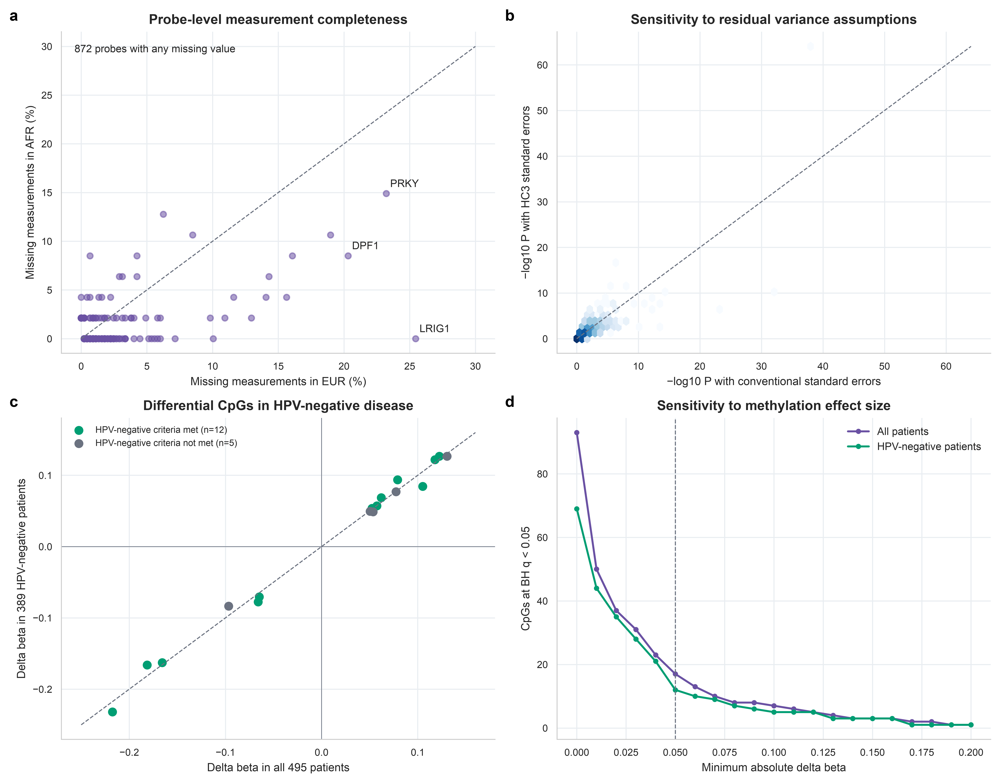

**supplementary figureS2 regulatory coupling robustness**

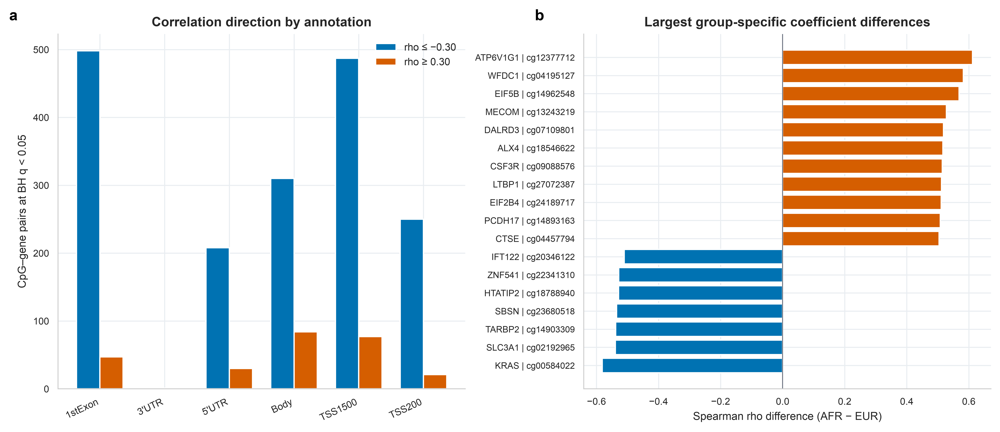

**supplementary figureS3 survival diagnostics**

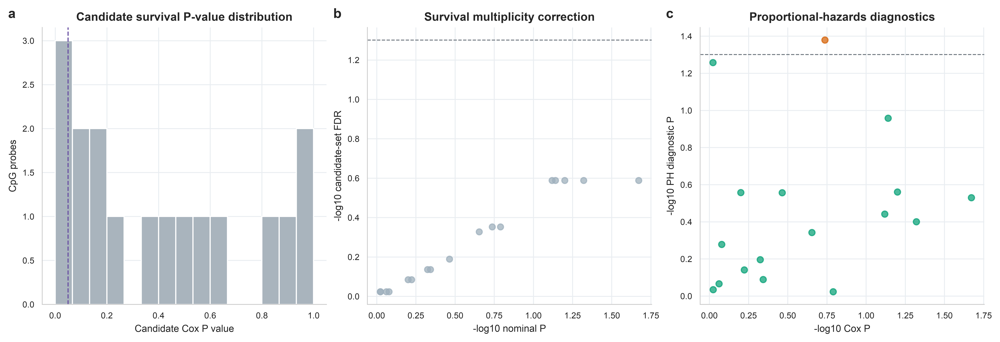

In [10]:
pipeline.figures()
figure_paths = sorted(FIGURES.glob("*.png"))
if not figure_paths:
    raise FileNotFoundError("The figure stage produced no PNG files.")
for figure_path in figure_paths:
    display(Markdown(f"**{figure_path.stem.replace('_', ' ')}**"))
    display(Image(filename=str(figure_path), width=1000))

## 11. Validate the run

Inspect the validation report together with the tables and
figure source data. Agreement with the saved reference results
verifies this implementation against the manuscript analysis;
it does not provide external cohort validation. Exploratory
permutation settings should remain clearly labelled.

In [11]:
validation = pipeline.validate_results()
display(validation)

validate_results: complete (0.2 s)


,check,passed,observed,expected
0,patients,True,4.950000e+02,495
1,AFR patients,True,4.700000e+01,47
2,EUR patients,True,4.480000e+02,448
3,unique input probes,True,2.260100e+04,22601
4,eligible probes,True,2.179100e+04,21791
5,BH-significant probes,True,9.300000e+01,93
6,differential probes meeting effect criterion,True,1.700000e+01,17
7,RNA-matched patients,True,4.870000e+02,487
8,finite full-cohort expression tests,True,2.422400e+04,24224
9,full-cohort expression associations,True,2.014000e+03,2014


## Outputs and attribution

Generated tables, figures, figure source data and validation
records are in the configured output folder. Reuse the same
package functions from other notebooks or the command-line
interface described in the README.

Cite the software using `CITATION.cff`, the original TCGA HNSC
study (PMID **25631445**), and the Infinium probe-annotation
resource (PMID **27924034**). Consult `data/` provenance
documentation for the precise input files, checksums, sources
and source-specific reuse terms. The code license does not
replace the terms for third-party data.